# 랭그래프에서 장기 메모리 사용하기

## 세팅

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

# Access the store inside nodes

https://docs.langchain.com/oss/python/langgraph/add-memory#access-the-store-inside-nodes

스토어를 포함하여 그래프를 컴파일하면 LangGraph는 자동으로 노드 함수에 스토어를 주입합니다. 

스토어에 접근하는 가장 좋은 방법은 Runtime객체를 통하는 것입니다.


In [9]:
# 필요 패키지 설치 (최초 1회만 실행)
# %pip install -U langgraph langchain-openai

import os
import uuid
from dataclasses import dataclass

from langchain_openai import ChatOpenAI                 # OpenAI 챗 모델
from langgraph.runtime import Runtime                   # 노드에서 context/store 접근용 Runtime
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.store.memory import InMemoryStore        # 장기 기억(long-term memory) 저장소
from langgraph.checkpoint.memory import InMemorySaver   # 단기 기억(thread_id 기반 체크포인터)


# 그래프 전체에서 공유할 장기 기억 저장소 생성
store = InMemoryStore()

# thread_id 단위로 대화 상태를 저장하는 체크포인터 생성
checkpointer = InMemorySaver()

# 모델 인스턴스 생성
llm = ChatOpenAI(model="gpt-5-mini")


# 실행 시점에 주입되는 런타임 컨텍스트 스키마 정의
@dataclass
class Context:
    user_id: str


# 장기 기억을 검색/저장하면서 모델을 호출하는 노드
async def call_model(state: MessagesState, runtime: Runtime[Context]):
    # 런타임 컨텍스트에서 사용자 ID 추출
    user_id = runtime.context.user_id

    # 사용자별 기억을 구분하는 네임스페이스 (튜플 형태)
    namespace = (user_id, "memories")

    # 마지막 사용자 메시지를 쿼리로 사용해 관련 기억 검색 (최대 3개)
    memories = await runtime.store.asearch(
        namespace, query=state["messages"][-1].content, limit=3
    )

    # 검색된 기억들을 문자열 하나로 합침
    info = "\n".join([d.value["data"] for d in memories])

    # 검색된 기억을 시스템 메시지로 넣고 모델 호출
    system_msg = f"You are a helpful assistant. User info:\n{info}"
    response = await llm.ainvoke(
        [{"role": "system", "content": system_msg}] + state["messages"]
    )

    # 새로운 기억을 저장 (키는 UUID로 생성)
    await runtime.store.aput(
        namespace, str(uuid.uuid4()), {"data": "User prefers dark mode"}
    )

    # 모델 응답을 상태에 추가
    return {"messages": [response]}


# 그래프 구성: 상태 스키마 + 컨텍스트 스키마 지정
builder = StateGraph(MessagesState, context_schema=Context)
builder.add_node(call_model)
builder.add_edge(START, "call_model")

# store(장기 기억)와 checkpointer(단기 기억)를 함께 컴파일
graph = builder.compile(store=store, checkpointer=checkpointer)

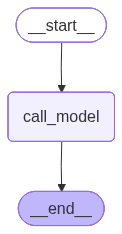

In [4]:
graph

테스트

In [5]:
# 첫 번째 호출: 기억이 비어 있는 상태에서 대화 시작
result = await graph.ainvoke(
    {"messages": [{"role": "user", "content": "hi"}]},
    {"configurable": {"thread_id": "1"}},
    context=Context(user_id="1"),
)
print(result["messages"][-1].content)

Hello! How can I assist you today?


In [6]:
# 두 번째 호출: 첫 호출에서 저장된 "dark mode" 기억이 검색되어 활용됨
result = await graph.ainvoke(
    {"messages": [{"role": "user", "content": "내가 선호하는 화면 모드가 뭐야?"}]},
    {"configurable": {"thread_id": "2"}},  # 다른 thread여도 store 기억은 공유됨
    context=Context(user_id="1"),
)
print(result["messages"][-1].content)

당신은 어두운 모드(다크 모드)를 선호합니다.


In [7]:
# store에 실제로 저장된 기억 확인
items = store.search(("1", "memories"))
for item in items:
    print(item.key, "→", item.value)

cb4986a8-9b5b-4a9b-98ff-4bb316f083c9 → {'data': 'User prefers dark mode'}
10060da1-e216-40e2-aca0-cc3ef47589e8 → {'data': 'User prefers dark mode'}


# Use semantic search

https://docs.langchain.com/oss/python/langgraph/add-memory#use-semantic-search


그래프 에이전트가 의미 유사성을 기준으로 저장소의 항목을 검색할 수 있도록 

그래프의 메모리 저장소에서 의미 검색을 활성화하십시오.

In [10]:
from langchain.embeddings import init_embeddings          # 임베딩 모델 초기화 함수
from langchain.chat_models import init_chat_model          # 챗 모델 초기화 함수
from langgraph.store.memory import InMemoryStore           # 장기 기억 저장소
from langgraph.graph import START, MessagesState, StateGraph
from langgraph.runtime import Runtime                      # 노드에서 store 접근용 Runtime

# 챗 모델 생성
model = init_chat_model("gpt-5.4-mini")

# 시맨틱 검색(의미 기반 검색)이 활성화된 store 생성
embeddings = init_embeddings("openai:text-embedding-3-small")
store = InMemoryStore(
    index={
        "embed": embeddings,   # 검색에 사용할 임베딩 모델
        "dims": 1536,          # 임베딩 벡터 차원 수
    }
)

# 사용자 기억을 미리 저장 (네임스페이스, 키, 값)
store.put(("user_123", "memories"), "1", {"text": "나는 피자를 좋아해"})
store.put(("user_123", "memories"), "2", {"text": "나는 배관공이야"})


# 기억을 검색한 뒤 모델을 호출하는 노드
async def chat(state: MessagesState, runtime: Runtime):
    # 사용자의 마지막 메시지를 쿼리로 사용해 관련 기억을 최대 2개 검색
    items = await runtime.store.asearch(
        ("user_123", "memories"), query=state["messages"][-1].content, limit=2
    )

    # 검색된 기억들을 하나의 문자열로 합침
    memories = "\n".join(item.value["text"] for item in items)

    # 기억이 있으면 시스템 프롬프트에 넣을 형식으로 변환
    memories = f"## 사용자에 대한 기억\n{memories}" if memories else ""

    # 시스템 메시지(기억 포함) + 기존 대화를 모델에 전달
    response = await model.ainvoke(
        [
            {"role": "system", "content": f"당신은 도움이 되는 어시스턴트입니다.\n{memories}"},
            *state["messages"],
        ]
    )

    # 모델 응답을 상태에 추가
    return {"messages": [response]}


# 그래프 구성
builder = StateGraph(MessagesState)
builder.add_node(chat)
builder.add_edge(START, "chat")

# store를 연결해 컴파일
graph = builder.compile(store=store)



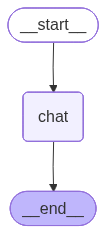

In [11]:
graph 

In [12]:
# 이벤트 스트리밍 실행 (v3 버전)
stream = await graph.astream_events(
    {"messages": [{"role": "user", "content": "배고파"}]},
    version="v3",
)

# 스트리밍된 메시지를 순회
async for message in stream.messages:
    # 메시지의 텍스트 토큰을 순회하며 출력
    async for token in message.text:
        print(token, end="", flush=True)

배고프시군요. 뭐라도 빨리 드시는 게 좋겠어요.

지금 바로 가능하면:
- 빵, 과일, 요거트 같은 간단한 것
- 밥/면 있으면 한 그릇
- 물도 먼저 한 컵

피자 좋아하시면, 오늘은 **피자 한 판 시키기**도 꽤 좋은 선택이에요.  
원하시면 **지금 있는 재료로 5분 안에 먹을 것** 같이 골라드릴게요.